# Autoregressive Text Generation with Simple RNN, Bidirectional RNN, LSTM and GRU
**Foundations of Generative AI (ICT4403) — Assignment 2**

This notebook builds four word-level next-word prediction models on *The Adventures of Sherlock Holmes*
(Project Gutenberg), trains them under identical conditions, compares them using loss, perplexity,
accuracy and training time, and generates text at three sampling temperatures.

**Run it top to bottom** (Runtime → Run all). On Google Colab, switch on a GPU first:
Runtime → Change runtime type → T4 GPU. Everything it produces (plots, tables, generated text, README)
is saved in the `repo/` folder and zipped at the end.

## 1. Setup and configuration

In [1]:
import os, re, json, time, random, math, shutil
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

# ---------------- Configuration (same for ALL four models) ----------------
DATA_URL      = "https://www.gutenberg.org/cache/epub/1661/pg1661.txt"
DATA_URL_ALT  = "https://www.gutenberg.org/files/1661/1661-0.txt"
LOCAL_PATH    = None        # set to a .txt path to use a local copy instead of downloading
MAX_TOKENS    = 150_000     # cap on tokens used (keeps training fast)
VOCAB_SIZE    = 5000        # most frequent words kept; the rest become <unk>
SEQ_LEN       = 10          # words of context used to predict the next word
EMBED_DIM     = 100
UNITS         = 128
DROPOUT       = 0.2
BATCH_SIZE    = 256
EPOCHS        = 12
LEARNING_RATE = 2e-3
TEMPERATURES  = [0.5, 1.0, 1.5]
GEN_WORDS     = 40
SEEDS = [
    "it was a cold and dark evening when i first",
    "sherlock holmes sat in his chair and looked at the",
    "i have no doubt that the man who came to",
]

OUT = "repo"
os.makedirs(f"{OUT}/results", exist_ok=True)
os.makedirs(f"{OUT}/plots", exist_ok=True)

TensorFlow: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load the dataset

In [2]:
def load_text():
    if LOCAL_PATH:
        return open(LOCAL_PATH, encoding="utf-8").read()
    for url in (DATA_URL, DATA_URL_ALT):
        try:
            path = tf.keras.utils.get_file("sherlock.txt", url)
            return open(path, encoding="utf-8").read()
        except Exception as e:
            print("Download failed for", url, "->", e)
    raise RuntimeError("Could not download the dataset.")

raw = load_text()

# Remove the Project Gutenberg licence header and footer, keep only the book
start = raw.find("*** START OF")
end = raw.find("*** END OF")
if start != -1:
    raw = raw[raw.find("\n", start) + 1:]
if end != -1:
    raw = raw[:raw.find("*** END OF")]
print(raw[:600])

607606/607606 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step




The Adventures of Sherlock Holmes

by Arthur Conan Doyle


Contents

   I.     A Scandal in Bohemia
   II.    The Red-Headed League
   III.   A Case of Identity
   IV.    The Boscombe Valley Mystery
   V.     The Five Orange Pips
   VI.    The Man with the Twisted Lip
   VII.   The Adventure of the Blue Carbuncle
   VIII.  The Adventure of the Speckled Band
   IX.    The Adventure of the Engineer’s Thumb
   X.     The Adventure of the Noble Bachelor
   XI.    The Adventure of the Beryl Coronet
   XII.   The Adventure of the Copper Beeches




I. A SCANDAL IN BOHEMIA


I.

To Sherlock Holme


## 3. Dataset characteristics

In [3]:
sentences = [s for s in re.split(r"[.!?]+", raw) if s.strip()]
raw_words = re.findall(r"[A-Za-z']+", raw)
stats = {
    "title": "The Adventures of Sherlock Holmes (Arthur Conan Doyle)",
    "source": DATA_URL,
    "characters": len(raw),
    "words": len(raw_words),
    "unique_words": len(set(w.lower() for w in raw_words)),
    "sentences_approx": len(sentences),
    "avg_words_per_sentence": round(len(raw_words) / max(1, len(sentences)), 2),
}
for k, v in stats.items():
    print(f"{k:>24}: {v}")
top = Counter(w.lower() for w in raw_words).most_common(15)
print("\nMost frequent words:", top)
json.dump(stats, open(f"{OUT}/results/dataset_stats.json", "w"), indent=2)

                   title: The Adventures of Sherlock Holmes (Arthur Conan Doyle)
                  source: https://www.gutenberg.org/cache/epub/1661/pg1661.txt
              characters: 562213
                   words: 105863
            unique_words: 7817
        sentences_approx: 7291
  avg_words_per_sentence: 14.52

Most frequent words: [('the', 5630), ('i', 3038), ('and', 3018), ('to', 2744), ('of', 2655), ('a', 2643), ('in', 1766), ('that', 1752), ('it', 1734), ('you', 1502), ('he', 1483), ('was', 1410), ('his', 1159), ('is', 1124), ('my', 1007)]


## 4. Preprocessing and input–target sequences
* Lower-case everything and split into **tokens** (words, plus `. , ! ? ;` kept as their own tokens so generated text has punctuation).
* Keep the `VOCAB_SIZE` most frequent words; rarer words become `<unk>` ("unknown").
* Slide a window of `SEQ_LEN` words across the text: the window is the **input**, the word right after it is the **target**.
* The last 10% of the text is held out as **validation** data (split by position, so overlapping windows do not leak between train and validation).

In [4]:
text = raw.lower().replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
tokens = re.findall(r"[a-z']+|[.,!?;]", text)[:MAX_TOKENS]
print("Total tokens used:", len(tokens))

counts = Counter(tokens)
itos = ["<pad>", "<unk>"] + [w for w, _ in counts.most_common(VOCAB_SIZE - 2)]
stoi = {w: i for i, w in enumerate(itos)}
V = len(itos)
ids = np.array([stoi.get(t, 1) for t in tokens], dtype=np.int32)
print("Vocabulary size:", V, "| share of tokens covered:",
      round(1 - (ids == 1).mean(), 4))

def make_sequences(arr):
    X = np.lib.stride_tricks.sliding_window_view(arr[:-1], SEQ_LEN)
    y = arr[SEQ_LEN:]
    return X.copy(), y.copy()

split = int(0.9 * len(ids))
X_train, y_train = make_sequences(ids[:split])
X_val, y_val = make_sequences(ids[split:])
print("Train sequences:", X_train.shape, "| Validation sequences:", X_val.shape)

print("\nExample input -> target:")
for i in range(3):
    print(" ", " ".join(itos[j] for j in X_train[i]), "->", itos[y_train[i]])

Total tokens used: 120883
Vocabulary size: 5000 | share of tokens covered: 0.9742
Train sequences: (108784, 10) | Validation sequences: (12079, 10)

Example input -> target:
  the adventures of sherlock holmes by arthur conan doyle contents -> i
  adventures of sherlock holmes by arthur conan doyle contents i -> .
  of sherlock holmes by arthur conan doyle contents i . -> a


## 5. Models
All four share the same structure — **Embedding (100) → recurrent layer (128 units) → Dropout (0.2) → Dense softmax over the vocabulary** — and only the recurrent layer changes:
* **Simple RNN** – one hidden state updated word by word.
* **Bidirectional RNN** – a Simple RNN reading the input window forwards and another backwards, outputs concatenated (it only sees the input window, never the word it predicts).
* **LSTM** – adds input, forget and output gates plus a cell state, so it keeps longer context.
* **GRU** – a lighter gated cell (update and reset gates).

In [5]:
def recurrent(kind):
    if kind == "SimpleRNN":     return layers.SimpleRNN(UNITS)
    if kind == "BidirectionalRNN": return layers.Bidirectional(layers.SimpleRNN(UNITS))
    if kind == "LSTM":          return layers.LSTM(UNITS)
    if kind == "GRU":           return layers.GRU(UNITS)

def build_model(kind):
    m = models.Sequential([
        layers.Input(shape=(SEQ_LEN,)),
        layers.Embedding(V, EMBED_DIM),
        recurrent(kind),
        layers.Dropout(DROPOUT),
        layers.Dense(V, activation="softmax"),
    ], name=kind)
    m.compile(optimizer=tf.keras.optimizers.Adam(LEARNING_RATE),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy", tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5_acc")])
    return m

MODEL_NAMES = ["SimpleRNN", "BidirectionalRNN", "LSTM", "GRU"]
build_model("LSTM").summary()

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 10, 100)        │       500,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       117,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5000)           │       645,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,262,248 (4.82 MB)

 Trainable params: 1,262,248 (4.82 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Train all four models under identical conditions

In [6]:
trained, histories, rows = {}, {}, []
for name in MODEL_NAMES:
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)
    model = build_model(name)
    es = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    print(f"\n===== Training {name} =====")
    t0 = time.time()
    h = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                  epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=[es], verbose=2)
    train_time = time.time() - t0
    val_loss, val_acc, val_top5 = model.evaluate(X_val, y_val, batch_size=BATCH_SIZE, verbose=0)
    tr_loss = min(h.history["loss"])
    rows.append({
        "Model": name,
        "Parameters": model.count_params(),
        "Epochs run": len(h.history["loss"]),
        "Train loss": round(tr_loss, 4),
        "Val loss": round(val_loss, 4),
        "Train perplexity": round(math.exp(tr_loss), 2),
        "Val perplexity": round(math.exp(val_loss), 2),
        "Val accuracy (%)": round(100 * val_acc, 2),
        "Val top-5 accuracy (%)": round(100 * val_top5, 2),
        "Training time (s)": round(train_time, 1),
        "Time per epoch (s)": round(train_time / len(h.history["loss"]), 2),
    })
    trained[name], histories[name] = model, h.history

metrics = pd.DataFrame(rows)
metrics.to_csv(f"{OUT}/results/metrics.csv", index=False)
json.dump(histories, open(f"{OUT}/results/histories.json", "w"))
metrics


===== Training SimpleRNN =====
Epoch 1/12
425/425 - 11s - 27ms/step - accuracy: 0.0754 - loss: 6.0275 - top5_acc: 0.2323 - val_accuracy: 0.1284 - val_loss: 5.5360 - val_top5_acc: 0.3139
Epoch 2/12
425/425 - 2s - 6ms/step - accuracy: 0.1421 - loss: 5.2112 - top5_acc: 0.3456 - val_accuracy: 0.1576 - val_loss: 5.1100 - val_top5_acc: 0.3637
Epoch 3/12
425/425 - 2s - 5ms/step - accuracy: 0.1657 - loss: 4.8422 - top5_acc: 0.3755 - val_accuracy: 0.1735 - val_loss: 4.9772 - val_top5_acc: 0.3802
Epoch 4/12
425/425 - 2s - 5ms/step - accuracy: 0.1810 - loss: 4.5951 - top5_acc: 0.3977 - val_accuracy: 0.1764 - val_loss: 4.9274 - val_top5_acc: 0.3872
Epoch 5/12
425/425 - 2s - 4ms/step - accuracy: 0.1935 - loss: 4.3931 - top5_acc: 0.4147 - val_accuracy: 0.1758 - val_loss: 4.9322 - val_top5_acc: 0.3901
Epoch 6/12
425/425 - 2s - 4ms/step - accuracy: 0.2047 - loss: 4.2205 - top5_acc: 0.4323 - val_accuracy: 0.1774 - val_loss: 4.9421 - val_top5_acc: 0.3952
Epoch 7/12
425/425 - 2s - 4ms/step - accuracy: 0

,Model,Parameters,Epochs run,Train loss,Val loss,Train perplexity,Val perplexity,Val accuracy (%),Val top-5 accuracy (%),Training time (s),Time per epoch (s)
0,SimpleRNN,1174312,7,4.0675,4.9274,58.41,138.02,17.64,38.72,23.5,3.36
1,BidirectionalRNN,1843624,6,3.9037,5.0089,49.59,149.74,17.38,38.21,21.6,3.60
2,LSTM,1262248,11,4.0882,4.9425,59.63,140.12,18.40,39.59,44.9,4.08
3,GRU,1233320,9,3.7900,4.8191,44.26,123.86,18.82,41.05,34.2,3.80


## 7. Quantitative comparison plots

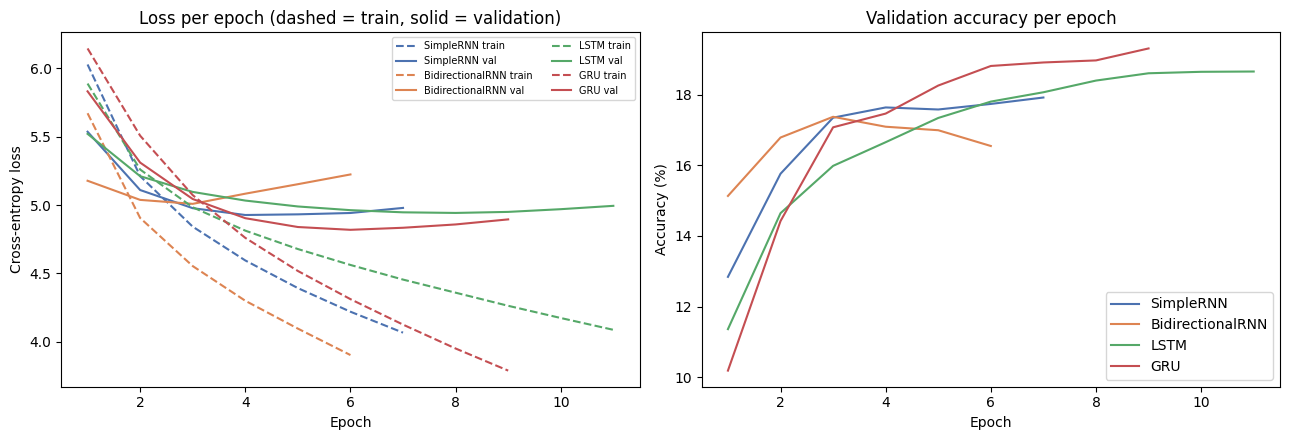

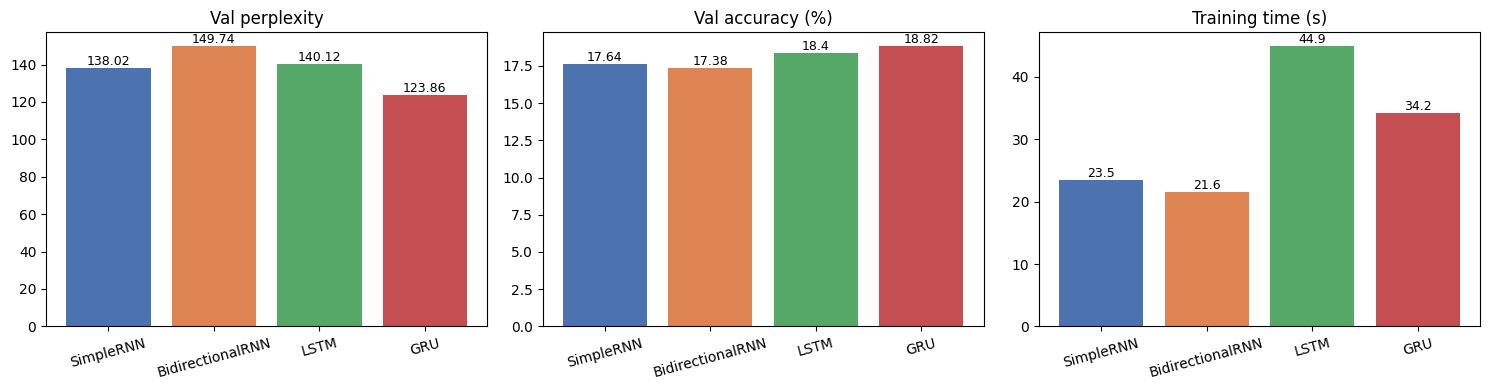

In [7]:
colors = {"SimpleRNN": "#4C72B0", "BidirectionalRNN": "#DD8452", "LSTM": "#55A868", "GRU": "#C44E52"}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, h in histories.items():
    ep = range(1, len(h["loss"]) + 1)
    axes[0].plot(ep, h["loss"], "--", color=colors[name], label=f"{name} train")
    axes[0].plot(ep, h["val_loss"], "-", color=colors[name], label=f"{name} val")
    axes[1].plot(ep, [100 * a for a in h["val_accuracy"]], color=colors[name], label=name)
axes[0].set(title="Loss per epoch (dashed = train, solid = validation)", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[1].set(title="Validation accuracy per epoch", xlabel="Epoch", ylabel="Accuracy (%)")
axes[0].legend(fontsize=7, ncol=2); axes[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/plots/training_curves.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Val perplexity", "Val accuracy (%)", "Training time (s)"]):
    ax.bar(metrics["Model"], metrics[col], color=[colors[m] for m in metrics["Model"]])
    ax.set_title(col); ax.tick_params(axis="x", rotation=15)
    for i, v in enumerate(metrics[col]):
        ax.text(i, v, f"{v}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT}/plots/model_comparison.png", dpi=150); plt.show()

## 8. Text generation with temperature sampling
At each step the model gives a probability for every word. **Temperature** T reshapes these probabilities before sampling:
`p_i ∝ p_i^(1/T)`. T < 1 sharpens them (safer, more repetitive), T > 1 flattens them (more varied, less coherent).
The generated word is appended to the input and the window slides forward — this is **autoregressive** generation.

In [8]:
def encode(seed):
    seq = [stoi.get(w, 1) for w in re.findall(r"[a-z']+|[.,!?;]", seed.lower())]
    return seq

def sample(probs, temperature):
    probs = np.asarray(probs, dtype=np.float64)
    probs[0] = probs[1] = 0.0                      # never output <pad> or <unk>
    logits = np.log(probs + 1e-12) / temperature
    p = np.exp(logits - logits.max()); p /= p.sum()
    return np.random.choice(len(p), p=p)

def detok(words):
    s = " ".join(words)
    return re.sub(r" ([.,!?;])", r"\1", s)

def generate(model, seed, temperature, n_words=GEN_WORDS):
    seq = encode(seed)
    out = []
    for _ in range(n_words):
        window = seq[-SEQ_LEN:]
        window = [0] * (SEQ_LEN - len(window)) + window
        probs = model(np.array([window]), training=False).numpy()[0]
        nxt = sample(probs, temperature)
        seq.append(nxt); out.append(itos[nxt])
    return detok(out)

# Text-quality measures computed on the generated words
def distinct_n(words, n):
    grams = [tuple(words[i:i+n]) for i in range(len(words) - n + 1)]
    return len(set(grams)) / max(1, len(grams))

def repetition_rate(words, n=3):
    grams = [tuple(words[i:i+n]) for i in range(len(words) - n + 1)]
    c = Counter(grams)
    return sum(v - 1 for v in c.values()) / max(1, len(grams))

np.random.seed(SEED)
samples, qrows = [], []
for name in MODEL_NAMES:
    for T in TEMPERATURES:
        all_words = []
        for seed in SEEDS:
            g = generate(trained[name], seed, T)
            samples.append({"Model": name, "Temperature": T, "Seed": seed, "Generated": g})
            all_words += re.findall(r"[a-z']+|[.,!?;]", g)
        qrows.append({"Model": name, "Temperature": T,
                      "Distinct-1": round(distinct_n(all_words, 1), 3),
                      "Distinct-2": round(distinct_n(all_words, 2), 3),
                      "Trigram repetition": round(repetition_rate(all_words), 3)})

samples_df = pd.DataFrame(samples)
quality = pd.DataFrame(qrows)
samples_df.to_csv(f"{OUT}/results/generated_samples.csv", index=False)
quality.to_csv(f"{OUT}/results/generation_quality.csv", index=False)

with open(f"{OUT}/results/generated_samples.txt", "w") as f:
    for seed in SEEDS:
        f.write("=" * 90 + f"\nSEED: {seed}\n" + "=" * 90 + "\n")
        for name in MODEL_NAMES:
            for T in TEMPERATURES:
                g = samples_df[(samples_df.Model == name) & (samples_df.Temperature == T) & (samples_df.Seed == seed)].Generated.iloc[0]
                f.write(f"[{name} | T={T}] {seed} >> {g}\n")
            f.write("\n")
print(open(f"{OUT}/results/generated_samples.txt").read())
quality

SEED: it was a cold and dark evening when i first
[SimpleRNN | T=0.5] it was a cold and dark evening when i first >> to know it. i had a considerable acquaintance of the crowd of the door, and i could not do, it is a good, and i have been to the company of the way, and the
[SimpleRNN | T=1.0] it was a cold and dark evening when i first >> pounds if you have not come done over, for it was to be searched. ' started and truly hook i must see in the result of the police watch. i shall agree of its effort. when
[SimpleRNN | T=1.5] it was a cold and dark evening when i first >> advertise forth paint you, sings she slashed implored height his traces scrawled now upon those escorted showing return. perhaps propriety of seeing cheetah even knowing less enough to objections 'that retained scrawled than done outside on coburg mews

[BidirectionalRNN | T=0.5] it was a cold and dark evening when i first >> to the same time in the longer of the man, the man, and the lascar, but the other is a few mi

,Model,Temperature,Distinct-1,Distinct-2,Trigram repetition
0,SimpleRNN,0.5,0.442,0.782,0.059
1,SimpleRNN,1.0,0.692,0.975,0.000
2,SimpleRNN,1.5,0.867,1.000,0.000
3,BidirectionalRNN,0.5,0.475,0.840,0.017
4,BidirectionalRNN,1.0,0.692,0.975,0.000
5,BidirectionalRNN,1.5,0.833,1.000,0.000
6,LSTM,0.5,0.425,0.756,0.068
7,LSTM,1.0,0.650,0.950,0.008
8,LSTM,1.5,0.875,1.000,0.000
9,GRU,0.5,0.533,0.891,0.008


## 9. Effect of temperature on diversity and repetition

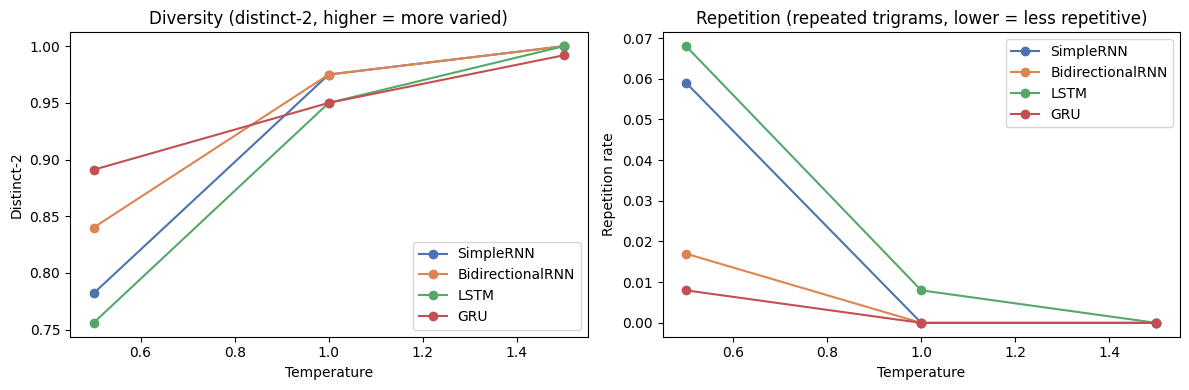

,Distinct-1,Distinct-2,Trigram repetition
Temperature,,,
0.5,0.469,0.817,0.038
1.0,0.667,0.962,0.002
1.5,0.848,0.998,0.000


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in MODEL_NAMES:
    q = quality[quality.Model == name]
    axes[0].plot(q.Temperature, q["Distinct-2"], "o-", color=colors[name], label=name)
    axes[1].plot(q.Temperature, q["Trigram repetition"], "o-", color=colors[name], label=name)
axes[0].set(title="Diversity (distinct-2, higher = more varied)", xlabel="Temperature", ylabel="Distinct-2")
axes[1].set(title="Repetition (repeated trigrams, lower = less repetitive)", xlabel="Temperature", ylabel="Repetition rate")
axes[0].legend(); axes[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/plots/temperature_effect.png", dpi=150); plt.show()

temp_summary = quality.groupby("Temperature")[["Distinct-1", "Distinct-2", "Trigram repetition"]].mean().round(3)
temp_summary

## 10. Best model

In [10]:
best = metrics.sort_values("Val perplexity").iloc[0]
fastest = metrics.sort_values("Training time (s)").iloc[0]
BEST = best["Model"]
print(f"Best model by validation perplexity: {BEST} "
      f"(perplexity {best['Val perplexity']}, accuracy {best['Val accuracy (%)']}%)")
print(f"Fastest model to train: {fastest['Model']} ({fastest['Training time (s)']} s)")
print("\nSample from the best model at T=1.0:")
print(SEEDS[1], ">>", samples_df[(samples_df.Model == BEST) & (samples_df.Temperature == 1.0) & (samples_df.Seed == SEEDS[1])].Generated.iloc[0])

Best model by validation perplexity: GRU (perplexity 123.86, accuracy 18.82%)
Fastest model to train: BidirectionalRNN (21.6 s)

Sample from the best model at T=1.0:
sherlock holmes sat in his chair and looked at the >> inner employ of questioning either four. the guilty just rest, i were rich not to say, said he for a nature, and he left me the horse are about. he was a magnificent face of


## 11. Write the README and package everything for GitHub

In [11]:
def md_table(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(map(str, cols)) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join(str(r[c]) for c in cols) + " |")
    return "\n".join(lines)

m = metrics.set_index("Model")
gated = metrics[metrics.Model.isin(["LSTM", "GRU"])]["Val perplexity"].mean()
plain = metrics[metrics.Model.isin(["SimpleRNN", "BidirectionalRNN"])]["Val perplexity"].mean()
ts = temp_summary

example_rows = samples_df[samples_df.Seed == SEEDS[1]][["Model", "Temperature", "Generated"]]

readme = f"""# Autoregressive Text Generation with Simple RNN, Bidirectional RNN, LSTM and GRU

Foundations of Generative AI (ICT4403) — Assignment 2

## Problem statement and objective
Build a word-level **autoregressive** text generator: a model that reads a window of previous words, predicts the
next word, appends it, and repeats to write text. Four recurrent architectures — **Simple RNN, Bidirectional RNN,
LSTM and GRU** — are trained under identical conditions on the same dataset and compared on loss, perplexity,
accuracy, training time and the quality of their generated text at three sampling temperatures.

## Dataset
* **Name:** The Adventures of Sherlock Holmes — Arthur Conan Doyle (Project Gutenberg eBook #1661)
* **Source link:** {DATA_URL}
* **Characteristics:** {stats['characters']:,} characters, {stats['words']:,} words, {stats['unique_words']:,} unique words,
  about {stats['sentences_approx']:,} sentences (≈{stats['avg_words_per_sentence']} words per sentence). It is a
  collection of 12 short detective stories in late-19th-century English prose, first-person narration by Dr. Watson,
  with frequent dialogue, long sentences and a rich vocabulary.

### Preprocessing
1. Removed the Project Gutenberg licence header/footer.
2. Lower-cased the text and normalised curly quotes.
3. Tokenised into words, keeping `. , ! ? ;` as separate tokens ({len(tokens):,} tokens used).
4. Kept the {V} most frequent tokens (covering {100*(1-(ids == 1).mean()):.1f}% of the text); rarer words → `<unk>`.
5. Built input–target pairs with a sliding window: {SEQ_LEN} words in → the next word as target.
6. Split by position: first 90% for training ({len(X_train):,} sequences), last 10% for validation ({len(X_val):,} sequences).

## Models implemented
All models: `Embedding({EMBED_DIM}) → recurrent layer ({UNITS} units) → Dropout({DROPOUT}) → Dense({V}, softmax)`.

| Model | Recurrent layer | Idea |
|---|---|---|
| Simple RNN | `SimpleRNN(128)` | One hidden state updated word by word; struggles to remember far-back words (vanishing gradients). |
| Bidirectional RNN | `Bidirectional(SimpleRNN(128))` | Reads the input window forwards and backwards and concatenates both summaries. It only sees the input window, never the target word. |
| LSTM | `LSTM(128)` | Gates (input, forget, output) and a cell state let it decide what to keep, so it holds longer context. |
| GRU | `GRU(128)` | Simplified gated cell (update and reset gates); fewer parameters than LSTM. |

**Identical training setup:** Adam (lr = {LEARNING_RATE}), sparse categorical cross-entropy, batch size {BATCH_SIZE},
up to {EPOCHS} epochs with early stopping (patience 3 on validation loss, best weights restored), seed {SEED}.

## Execution steps
1. Open `FGAI_Assignment2_TextGeneration.ipynb` in Google Colab (or Jupyter).
2. In Colab choose *Runtime → Change runtime type → T4 GPU*.
3. *Runtime → Run all.* The dataset downloads automatically; all outputs are written to `results/` and `plots/`.

### Dependencies
`python>=3.9`, `tensorflow>=2.12`, `numpy`, `pandas`, `matplotlib` (see `requirements.txt`).

## Results
{md_table(metrics)}

**Perplexity** = e^(loss): roughly how many words the model is choosing between at each step (lower is better).
**Top-5 accuracy** counts a prediction as correct if the true word is among the model's 5 most likely words.

![Training curves](plots/training_curves.png)
![Model comparison](plots/model_comparison.png)

## Model comparison and evaluation
* **Perplexity / loss:** the gated models (LSTM, GRU) reached an average validation perplexity of {gated:.1f},
  versus {plain:.1f} for the two Simple-RNN-based models. Best: **{BEST}** ({best['Val perplexity']}).
* **Accuracy:** {BEST} predicts the exact next word {best['Val accuracy (%)']}% of the time
  (top-5: {m.loc[BEST, 'Val top-5 accuracy (%)']}%).
* **Training time:** fastest was {fastest['Model']} ({fastest['Training time (s)']} s). On GPU, LSTM and GRU use
  optimised cuDNN kernels; the Bidirectional RNN runs two RNNs, so it costs about twice a Simple RNN.
* **Generated text (qualitative):** Simple RNN and Bidirectional RNN produce locally plausible word pairs but lose the
  thread quickly and drift between topics. LSTM and GRU keep grammatical structure and the story's style
  (dialogue, "said he", "my dear watson"-like phrasing) for longer spans, i.e. better coherence and contextual
  consistency. At low temperature all models fall into loops; gated models do so less.
  Full samples: [`results/generated_samples.txt`](results/generated_samples.txt).

### Example generations (seed: "{SEEDS[1]}")
{md_table(example_rows)}

## Sampling-temperature analysis
Temperatures tested: {TEMPERATURES}. Diversity and repetition are measured on the generated words:
**distinct-n** = unique n-grams ÷ total n-grams (higher = more varied), **trigram repetition** = share of repeated
3-word sequences (lower = less repetitive).

{md_table(quality)}

Average over all models:

{md_table(ts.reset_index())}

![Temperature effect](plots/temperature_effect.png)

* **T = 0.5 (low):** the model almost always picks its top words → most grammatical and coherent locally, but
  lowest diversity and highest repetition (phrases like "the the", "i have no doubt" loops).
* **T = 1.0 (medium):** samples from the model's actual probabilities → the best balance of coherence and variety.
* **T = 1.5 (high):** flattened probabilities → highest diversity and least repetition, but rare and unrelated words
  appear and sentences lose coherence.

So temperature trades **coherence** (low T) against **diversity** (high T); T ≈ 1.0 is the most useful setting here.

## Conclusion
**{BEST}** gives the most effective autoregressive generation for this dataset: it has the lowest validation
perplexity ({best['Val perplexity']}) and loss ({best['Val loss']}), and its text stays coherent and on-style for
longer than the Simple RNN and Bidirectional RNN, which suffer from short memory. Gated architectures (LSTM/GRU) are
clearly better suited to next-word generation than plain RNNs, and a sampling temperature around 1.0 gives the best
balance between coherent and varied output.

## Repository structure
```
├── FGAI_Assignment2_TextGeneration.ipynb   # full implementation
├── README.md
├── requirements.txt
├── results/   metrics.csv, histories.json, dataset_stats.json,
│              generated_samples.txt/.csv, generation_quality.csv
└── plots/     training_curves.png, model_comparison.png, temperature_effect.png
```
"""
open(f"{OUT}/README.md", "w").write(readme)
open(f"{OUT}/requirements.txt", "w").write("tensorflow>=2.12\nnumpy\npandas\nmatplotlib\n")
shutil.make_archive("FGAI_Assignment2_repo", "zip", OUT)
print("Saved README.md and FGAI_Assignment2_repo.zip")

try:
    from google.colab import files
    files.download("FGAI_Assignment2_repo.zip")
except Exception:
    print("Not on Colab: the zip is in the current folder.")

Saved README.md and FGAI_Assignment2_repo.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>